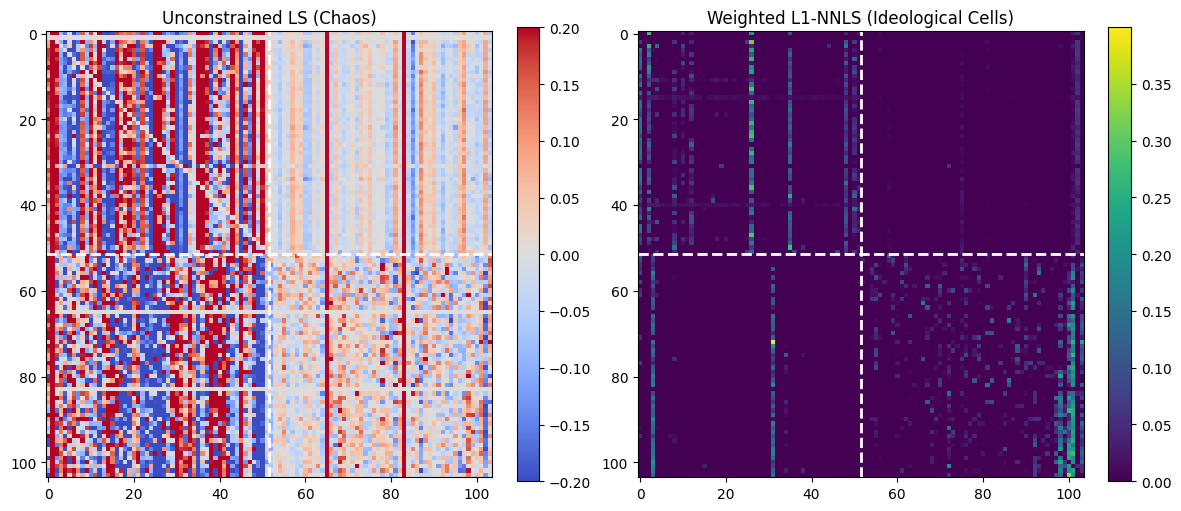


=== SENATE RESULTS ===
LS negative: 49.1%
NNLS negative: 0.0%
Senators: 104, Roll calls: 949


In [1]:
# ==========================================
# Analysis of US Senate Voting Data
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import nnls, minimize
import io, requests

print("Downloading Voteview data...")
votes_url = "https://voteview.com/static/data/out/votes/S117_votes.csv"
members_url = "https://voteview.com/static/data/out/members/S117_members.csv"

df = pd.read_csv(io.StringIO(requests.get(votes_url).text))
members = pd.read_csv(io.StringIO(requests.get(members_url).text))

df = df[df['cast_code'].isin([1, 6])]
pivot = df.pivot_table(index='rollnumber', columns='icpsr', values='cast_code', aggfunc='first').ffill().bfill()
X_raw = pivot.values
n_senators = X_raw.shape[1]

nominate_map = members.drop_duplicates('icpsr').set_index('icpsr')['nominate_dim1']
ideology = np.array([nominate_map.get(col, 0.0) for col in pivot.columns])

sort_idx = np.argsort(ideology)
X_raw = X_raw[:, sort_idx]
ideology = ideology[sort_idx]

X = X_raw - X_raw.min(axis=0) + 1e-6
X_lag = X[:-1, :]
Y_cur = X[1:, :]

dist_matrix = np.abs(ideology[:, None] - ideology[None, :])
dist_matrix = dist_matrix / (dist_matrix.max() + 1e-9)

W_nnls = np.zeros((n_senators, n_senators))
W_ls = np.zeros((n_senators, n_senators))

for i in range(n_senators):
    X_pred = X_lag.copy()
    X_pred[:, i] = 0.0
    w_i, _ = nnls(X_pred, Y_cur[:, i])
    W_nnls[i, :] = w_i
    w_ls, *_ = np.linalg.lstsq(X_pred, Y_cur[:, i], rcond=None)
    W_ls[i, :] = w_ls

scale_X, scale_Y = X_lag.max(), Y_cur.max()
X_lag_norm, Y_cur_norm = X_lag / scale_X, Y_cur / scale_Y
lambda_reg = 1.0
W_weighted = np.zeros((n_senators, n_senators))

for i in range(n_senators):
    X_pred = X_lag_norm.copy()
    X_pred[:, i] = 0.0
    y = Y_cur_norm[:, i]
    d = dist_matrix[i, :]
    def obj(w): return np.sum((X_pred @ w - y)**2) + lambda_reg * np.sum(d * w)
    def grad(w): return 2 * X_pred.T @ (X_pred @ w - y) + lambda_reg * d
    res = minimize(obj, np.zeros(n_senators), method='L-BFGS-B', jac=grad, bounds=[(0, None)]*n_senators)
    W_weighted[i, :] = res.x
W_weighted = W_weighted * (scale_Y / scale_X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(W_ls, cmap='coolwarm', vmin=-0.2, vmax=0.2)
axes[0].set_title('Unconstrained LS (Chaos)')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(W_weighted, cmap='viridis')
axes[1].set_title('Weighted L1-NNLS (Ideological Cells)')
for ax in axes:
    ax.axhline(n_senators//2 - 0.5, color='white', linestyle='--', linewidth=2)
    ax.axvline(n_senators//2 - 0.5, color='white', linestyle='--', linewidth=2)
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.show()

print("\n=== SENATE RESULTS ===")
print(f"LS negative: {(W_ls < 0).mean() * 100:.1f}%")
print(f"NNLS negative: {(W_nnls < 0).mean() * 100:.1f}%")
print(f"Senators: {X_raw.shape[1]}, Roll calls: {X_raw.shape[0]}")